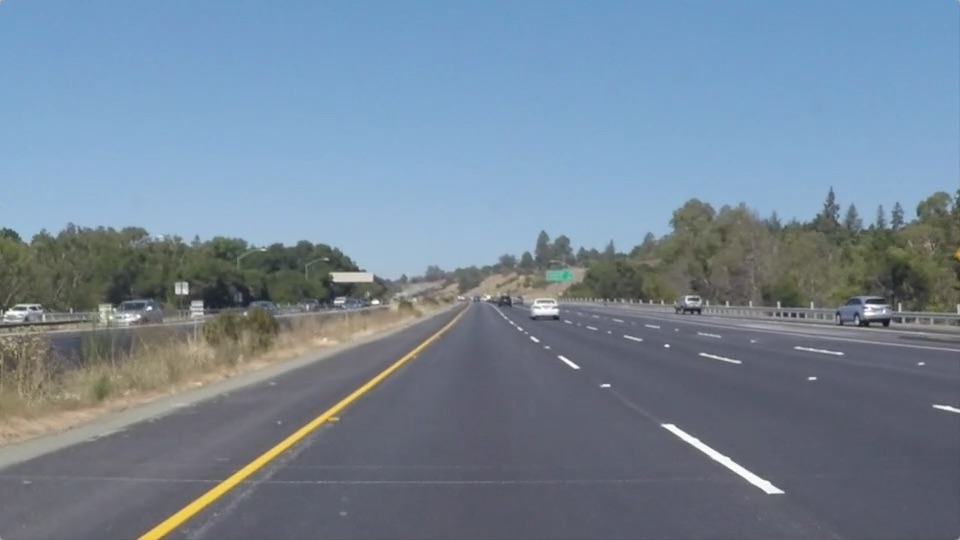

In [6]:
from pathlib import Path
from PIL import Image
import numpy as np
import torch
import numpy as np
import matplotlib.pyplot as plt

repo_dir = next(
    path
    for path in (Path("."), Path(".."), Path("../.."), Path("../../.."))
    if (path / "实践1" / "outer1.png").is_file()
)

# 读取图像，转换为numpy数组

image = Image.open(repo_dir / "实践1" / "outer1.png")
image = image.convert("RGB")
image_array = np.array(image)
display(image)

In [28]:
# 手写实现二维卷积运算，可同时处理灰度图像与RGB图像，参数padding表示填充大小
def conv2d(image, kernel, stride, padding):
    if image.ndim == 3:
        channels = []

        for c in range(3):
            channel = image[:, :, c]
            result = conv2d(channel, kernel, stride, padding)
            channels.append(result)

        return np.stack(channels, axis=2)
    
    else :
        H, W = image.shape
        KH, KW = kernel.shape
    
        if padding > 0:
            image = np.pad(
                image,
                ((padding, padding), (padding, padding)),
                mode="constant"
            )
    
        out_h = (H + 2 * padding - KH) // stride + 1
        out_w = (W + 2 * padding - KW) // stride + 1
    
        output = np.zeros((out_h, out_w), dtype=np.float32)
    
        for i in range(out_h):
            for j in range(out_w):
                row = i * stride
                col = j * stride
                region = image[row:row + KH, col:col + KW]
                output[i, j] = np.sum(region * kernel)

        return output

array([[[139, 161, 185],
        [131, 157, 185],
        [124, 156, 189],
        ...,
        [117, 155, 188],
        [124, 155, 183],
        [133, 160, 184]],

       [[131, 157, 185],
        [125, 155, 187],
        [120, 155, 191],
        ...,
        [112, 153, 188],
        [117, 152, 184],
        [123, 154, 182]],

       [[125, 157, 190],
        [120, 155, 191],
        [116, 155, 195],
        ...,
        [109, 153, 192],
        [112, 152, 187],
        [117, 152, 185]],

       ...,

       [[115, 114, 120],
        [109, 108, 114],
        [109, 108, 114],
        ...,
        [ 81,  83,  95],
        [ 82,  84,  96],
        [ 91,  92, 103]],

       [[120, 119, 124],
        [112, 111, 116],
        [111, 110, 115],
        ...,
        [ 82,  84,  95],
        [ 85,  86,  97],
        [ 99,  99, 109]],

       [[130, 129, 135],
        [119, 118, 123],
        [115, 114, 119],
        ...,
        [ 91,  92, 103],
        [ 99,  99, 109],
        [117, 117, 126]]

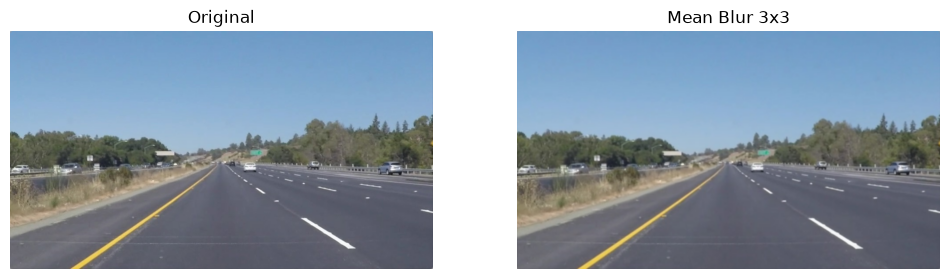

In [32]:
# 3×3均值模糊卷积核实验
def mean(stride, padding, show=1):
    mean_kernel = np.ones((3, 3), dtype=np.float32) / 9
    
    mean_result = conv2d(image_array, mean_kernel, stride, padding)
    # 裁剪超出显示范围的像素信息，保证正常显示
    mean_display = np.clip(mean_result, 0, 255).astype(np.uint8)

    if show:
        fig, axes = plt.subplots(1, 2, figsize=(12, 5))
        
        axes[0].imshow(image_array)
        axes[0].set_title("Original")
        axes[0].axis("off")
        
        axes[1].imshow(mean_display)
        axes[1].set_title("Mean Blur 3x3")
        axes[1].axis("off")
        
        plt.show()

    return mean_display

mean(1, 0)

array([[[125, 156, 188],
        [120, 155, 192],
        [116, 156, 196],
        ...,
        [109, 154, 194],
        [113, 153, 189],
        [118, 153, 184]],

       [[120, 156, 192],
        [117, 156, 195],
        [114, 156, 199],
        ...,
        [107, 154, 196],
        [109, 153, 192],
        [113, 152, 188]],

       [[116, 157, 196],
        [114, 157, 199],
        [111, 157, 202],
        ...,
        [105, 154, 199],
        [107, 153, 195],
        [109, 152, 192]],

       ...,

       [[109, 108, 114],
        [109, 108, 114],
        [109, 108, 114],
        ...,
        [ 82,  84,  97],
        [ 82,  84,  96],
        [ 83,  84,  97]],

       [[110, 109, 115],
        [109, 108, 114],
        [110, 109, 115],
        ...,
        [ 81,  83,  96],
        [ 81,  83,  96],
        [ 84,  86,  97]],

       [[114, 113, 118],
        [111, 110, 116],
        [111, 110, 116],
        ...,
        [ 82,  84,  96],
        [ 84,  85,  97],
        [ 89,  90, 101]]

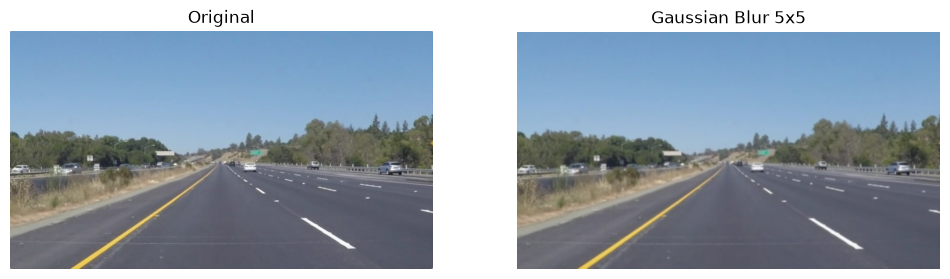

In [43]:
#  5×5高斯卷积核实验
def gaussian(stride, padding, show=1):
    gaussian_kernel = np.array([
        [1,  4,  6,  4, 1],
        [4, 16, 24, 16, 4],
        [6, 24, 36, 24, 6],
        [4, 16, 24, 16, 4],
        [1,  4,  6,  4, 1]
    ], dtype=np.float32) / 256
    
    gaussian_result = conv2d(image_array, gaussian_kernel, stride, padding)
    # 裁剪超出显示范围的像素信息，保证正常显示
    gaussian_display = np.clip(gaussian_result, 0, 255).astype(np.uint8)

    if show:
        fig, axes = plt.subplots(1, 2, figsize=(12, 5))
        
        axes[0].imshow(image_array)
        axes[0].set_title("Original")
        axes[0].axis("off")
        
        axes[1].imshow(gaussian_display)
        axes[1].set_title("Gaussian Blur 5x5")
        axes[1].axis("off")
        
        plt.show()

    return gaussian_display

gaussian(1, 0)

array([[[164, 182, 193],
        [135, 162, 189],
        [ 99, 127, 151],
        ...,
        [ 97, 127, 157],
        [123, 154, 186],
        [154, 174, 186]],

       [[135, 162, 189],
        [126, 151, 183],
        [108, 137, 178],
        ...,
        [103, 140, 174],
        [115, 149, 173],
        [116, 143, 175]],

       [[101, 129, 153],
        [111, 140, 181],
        [140, 181, 226],
        ...,
        [137, 181, 223],
        [ 97, 140, 172],
        [ 94, 127, 154]],

       ...,

       [[ 64,  63,  69],
        [107, 106, 112],
        [136, 135, 141],
        ...,
        [ 84,  86,  96],
        [ 77,  80,  94],
        [ 60,  56,  71]],

       [[105, 104, 111],
        [106, 105, 112],
        [ 81,  80,  87],
        ...,
        [ 80,  83,  98],
        [ 63,  74,  75],
        [ 45,  42,  51]],

       [[115, 114, 118],
        [103, 102, 106],
        [ 83,  82,  85],
        ...,
        [ 49,  45,  61],
        [ 52,  49,  58],
        [ 82,  82,  96]]

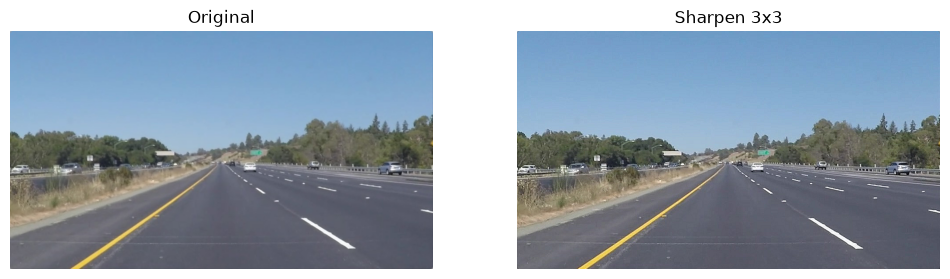

In [40]:
#  3×3锐化卷积核实验
def sharpen(stride, padding, show=1):
    sharpen_kernel = np.array([
        [ 0, -1,  0],
        [-1,  5, -1],
        [ 0, -1,  0]
    ], dtype=np.float32)
    
    sharpen_result = conv2d(image_array, sharpen_kernel, stride, padding)
    # 裁剪超出显示范围的像素信息，保证正常显示
    sharpen_display = np.clip(sharpen_result, 0, 255).astype(np.uint8)

    if show:
        fig, axes = plt.subplots(1, 2, figsize=(12, 5))
        
        axes[0].imshow(image_array)
        axes[0].set_title("Original")
        axes[0].axis("off")
        
        axes[1].imshow(sharpen_display)
        axes[1].set_title("Sharpen 3x3")
        axes[1].axis("off")
        
        plt.show()

    return sharpen_display

sharpen(1, 0)

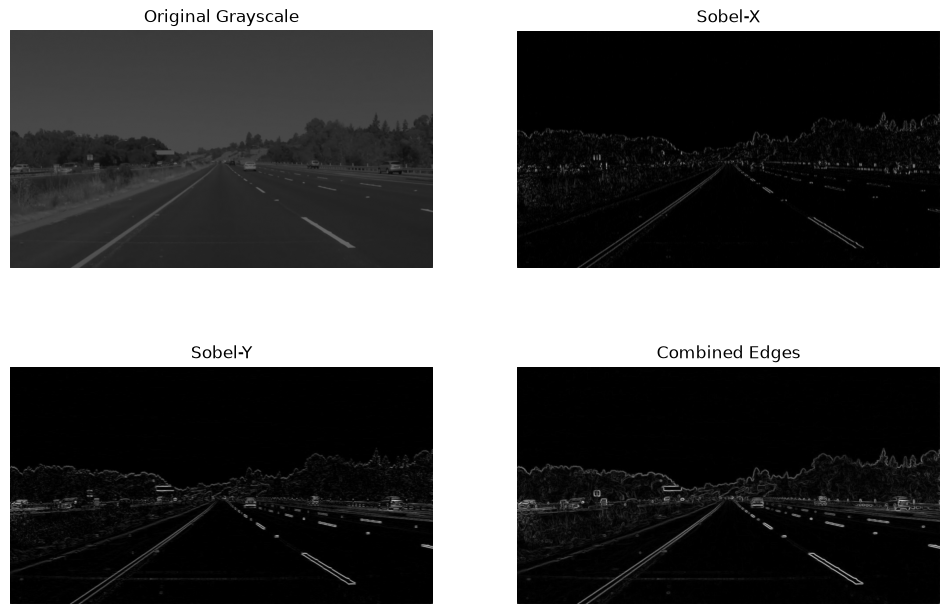

In [26]:
#  Sobel-X/Sobel-Y边缘检测实验
def sobel(stride, padding):
    gray_image = np.array(image.convert("L"))
    
    sobel_x = np.array([
        [-1, 0, 1],
        [-2, 0, 2],
        [-1, 0, 1]
    ], dtype=np.float32)
    
    sobel_y = np.array([
        [-1, -2, -1],
        [ 0,  0,  0],
        [ 1,  2,  1]
    ], dtype=np.float32)
    
    gx = conv2d(gray_image, sobel_x, stride, padding)
    gy = conv2d(gray_image, sobel_y, stride, padding)
    edges = np.hypot(gx, gy)
    
    max_gradient = edges.max()
    
    fig, axes = plt.subplots(2, 2, figsize=(12, 8))

    # 边缘检测结果取绝对值，灰度图映射范围统一，保证正常显示
    axes[0, 0].imshow(gray_image, cmap="gray", vmin=0, vmax=max_gradient)
    axes[0, 0].set_title("Original Grayscale")
    axes[0, 0].axis("off")
    
    axes[0, 1].imshow(np.abs(gx), cmap="gray", vmin=0, vmax=max_gradient)
    axes[0, 1].set_title("Sobel-X")
    axes[0, 1].axis("off")
    
    axes[1, 0].imshow(np.abs(gy), cmap="gray", vmin=0, vmax=max_gradient)
    axes[1, 0].set_title("Sobel-Y")
    axes[1, 0].axis("off")
    
    axes[1, 1].imshow(np.abs(edges), cmap="gray", vmin=0, vmax=max_gradient)
    axes[1, 1].set_title("Combined Edges")
    axes[1, 1].axis("off")
    
    plt.show()

sobel(1, 0)

array([[[164, 182, 193],
        [ 99, 151, 186],
        [115, 158, 198],
        ...,
        [107, 157, 194],
        [101, 153, 198],
        [ 97, 127, 157]],

       [[ 96, 148, 183],
        [116, 161, 205],
        [115, 157, 195],
        ...,
        [111, 155, 192],
        [105, 155, 201],
        [121, 168, 219]],

       [[115, 159, 199],
        [116, 158, 196],
        [117, 158, 197],
        ...,
        [106, 156, 199],
        [111, 153, 194],
        [110, 150, 194]],

       ...,

       [[107, 107, 117],
        [103, 103, 113],
        [109, 111, 122],
        ...,
        [ 79,  88, 101],
        [ 84,  88, 103],
        [ 85,  87, 102]],

       [[ 99,  98, 109],
        [105, 104, 115],
        [108, 109, 114],
        ...,
        [ 90,  90, 106],
        [ 80,  82,  97],
        [ 83,  85, 100]],

       [[ 64,  63,  69],
        [129, 128, 134],
        [115, 114, 118],
        ...,
        [ 90,  95, 104],
        [ 78,  80,  97],
        [ 84,  86,  96]]

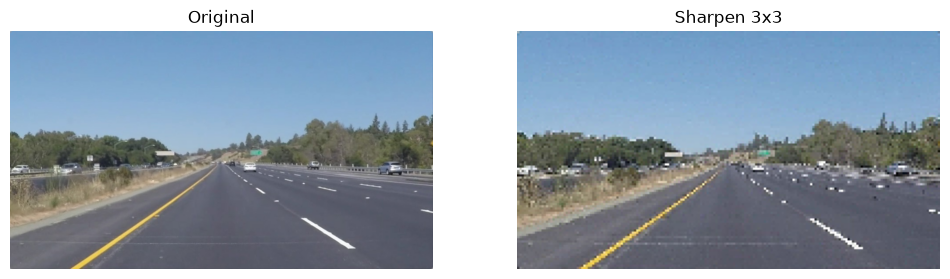

In [49]:
sharpen(5, 0)

In [47]:
# 部分padding与stride实验


print("mean填充实验:")
# 不填充，步幅1
mean_1 = mean(1, 0, 0)
print("不填充，步幅1")
print("原始尺寸：", image_array.shape)
print("处理后尺寸：", mean_1.shape)
print("左上角像素", mean_1[0, 0])

# 填充1，步幅1
mean_1 = mean(1, 1, 0)
print("\n填充1，步幅1")
print("原始尺寸：", image_array.shape)
print("处理后尺寸：", mean_1.shape)
print("左上角像素", mean_1[0, 0])


print("\nsharpen填充实验:")
# 不填充，步幅1
sharpen_1 = sharpen(1, 0, 0)
print("不填充，步幅1")
print("原始尺寸：", image_array.shape)
print("处理后尺寸：", sharpen_1.shape)
print("左上角像素", sharpen_1[0, 0])

# 填充1，步幅1
sharpen_1 = sharpen(1, 1, 0)
print("\n填充1，步幅1")
print("原始尺寸：", image_array.shape)
print("处理后尺寸：", sharpen_1.shape)
print("左上角像素", sharpen_1[0, 0])


print("\nsharpen步幅实验:")
# 填充1，步幅1
sharpen_1 = sharpen(1, 1, 0)
print("填充1，步幅1")
print("原始尺寸：", image_array.shape)
print("处理后尺寸：", sharpen_1.shape)
print("左上角像素", sharpen_1[0, 0])

# 填充1，步幅2
sharpen_1 = sharpen(2, 1, 0)
print("\n填充1，步幅2")
print("原始尺寸：", image_array.shape)
print("处理后尺寸：", sharpen_1.shape)
print("左上角像素", sharpen_1[0, 0])

mean填充实验:
不填充，步幅1
原始尺寸： (540, 960, 3)
处理后尺寸： (538, 958, 3)
左上角像素 [139 161 185]

填充1，步幅1
原始尺寸： (540, 960, 3)
处理后尺寸： (540, 960, 3)
左上角像素 [67 75 84]

sharpen填充实验:
不填充，步幅1
原始尺寸： (540, 960, 3)
处理后尺寸： (538, 958, 3)
左上角像素 [164 182 193]

填充1，步幅1
原始尺寸： (540, 960, 3)
处理后尺寸： (540, 960, 3)
左上角像素 [255 255 255]

gaussian步幅实验:
填充1，步幅1
原始尺寸： (540, 960, 3)
处理后尺寸： (540, 960, 3)
左上角像素 [255 255 255]

填充1，步幅2
原始尺寸： (540, 960, 3)
处理后尺寸： (270, 480, 3)
左上角像素 [255 255 255]
理论与多次实验表明，原始尺寸H、W,Kernel尺寸KH、KW,padding,stride,处理后尺寸out_h、out_w满足：
out_h = (H + 2 * padding - KH) // stride + 1
out_w = (W + 2 * padding - KW) // stride + 1


In [50]:
print("理论与多次实验表明，原始尺寸H、W,Kernel尺寸KH、KW,padding,stride与处理后尺寸out_h、out_w满足：")
print("out_h = (H + 2 * padding - KH) // stride + 1")
print("out_w = (W + 2 * padding - KW) // stride + 1")

理论与多次实验表明，原始尺寸H、W,Kernel尺寸KH、KW,padding,stride与处理后尺寸out_h、out_w满足：
out_h = (H + 2 * padding - KH) // stride + 1
out_w = (W + 2 * padding - KW) // stride + 1
